# Further analysis of inferred fitnesses

In [1]:
import numpy as np
import pandas as pd

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statannotations.Annotator import Annotator
from scipy import stats
from scipy.stats import expon, genpareto, chi2
import scikit_posthocs as sp
import statsmodels.formula.api as smf

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns
from venny4py.venny4py import *
import matplotlib.gridspec as gridspec

import random
import pysam
from numba import njit

In [2]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Load data

In [3]:
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")

#Get unique index for each mutation and count parallelism
data_unique = data.groupby(['pos', 'new']).size().reset_index(name='number_of_lines')
data_unique['Index'] = data_unique.index
data_indexed = pd.merge(data, data_unique, on=['pos', 'new'], how='left')

#Add cell type column
data_indexed['cell_type'] = np.floor((data_indexed['line']-13)/2)

#Get beneficial tail
data_ben = data_indexed[data_indexed['s']>0]

## Parallel mutations

In [4]:
#Randomisation tests (~4 minutes)
n_tests = 1e5
genome_length = 9665
p_12,p_13,p_14,p_23,p_24,p_34,p_123,p_124,p_134,p_234,p_1234 = 0,0,0,0,0,0,0,0,0,0,0

for i in range(int(n_tests)):
    n1 = random.sample(range(genome_length), 1049)
    n2 = random.sample(range(genome_length), 1143)
    n3 = random.sample(range(genome_length), 973)
    n4 = random.sample(range(genome_length), 927)

    p_12 += len(np.intersect1d(n1,n2))/n_tests
    p_13 += len(np.intersect1d(n1,n3))/n_tests
    p_14 += len(np.intersect1d(n1,n4))/n_tests
    p_23 += len(np.intersect1d(n2,n3))/n_tests
    p_24 += len(np.intersect1d(n2,n4))/n_tests
    p_34 += len(np.intersect1d(n3,n4))/n_tests

    p_123 += len(np.intersect1d(n1,np.intersect1d(n2,n3)))/n_tests
    p_124 += len(np.intersect1d(n1,np.intersect1d(n2,n4)))/n_tests
    p_134 += len(np.intersect1d(n1,np.intersect1d(n3,n4)))/n_tests
    p_234 += len(np.intersect1d(n2,np.intersect1d(n3,n4)))/n_tests

    p_1234 += len(np.intersect1d(n1,np.intersect1d(n2,np.intersect1d(n3,n4))))/n_tests

#Calculate labels
labels = np.zeros(19)
labels[18] = p_1234
labels[14] = p_123-p_1234
labels[15] = p_124-p_1234
labels[16] = p_134-p_1234
labels[17] = p_234-p_1234

labels[8] = p_12 - labels[14] - labels[15] - labels[18]
labels[9] = p_13 - labels[14] - labels[16] - labels[18]
labels[10] = p_14 - labels[15] - labels[16] - labels[18]
labels[11] = p_23 - labels[14] - labels[17] - labels[18]
labels[12] = p_24 - labels[15] - labels[17] - labels[18]
labels[13] = p_34 - labels[16] - labels[17] - labels[18]

labels[4] = 1049 - labels[8] - labels[9] - labels[10] - labels[14] - labels[15] - labels[16] - labels[18]
labels[5] = 1143 - labels[8] - labels[11] - labels[12] - labels[14] - labels[15] - labels[17] - labels[18]
labels[6] = 973 - labels[9] - labels[11] - labels[13] - labels[14] - labels[16] - labels[17] - labels[18]
labels[7] = 927 - labels[10] - labels[12] - labels[13] - labels[15] - labels[16] - labels[17] - labels[18]

labels[0] = 1049
labels[1] = 1143
labels[2] = 973
labels[3] = 927

labels = labels.round(0).astype(int)


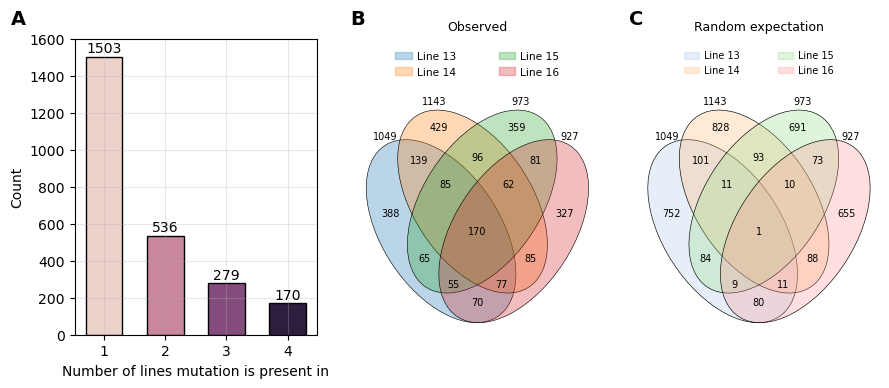

In [5]:
#Plot parallel mutations
fig, (ax1,ax2,ax3) = plt.subplots(1,3,figsize=(9,4))

#Histogram
counts, bins, patches = ax1.hist(data_unique['number_of_lines'],bins=[0.5,1.5,2.5,3.5,4.5],align='mid',rwidth=0.6,edgecolor='black')
colours = sns.color_palette("ch:", n_colors=4).as_hex()
for patch, colour in zip(patches, colours):
    patch.set_facecolor(colour)
ax1.bar_label(patches, padding=1)
ax1.grid(alpha=0.3)
ax1.set_xlabel('Number of lines mutation is present in')
ax1.set_ylabel('Count')
ax1.set_xticks(ticks=np.arange(1,5),labels=np.arange(1,5).astype(int))
ax1.set_ylim(0,1600)
ax1.text(-0.2, 1.1, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Venn diagram of observed mutations
sets = {'Line 13': set(data_indexed.loc[data_indexed['line'] == 13,'Index'].values),
        'Line 14': set(data_indexed.loc[data_indexed['line'] == 14,'Index'].values),
        'Line 15': set(data_indexed.loc[data_indexed['line'] == 15,'Index'].values),
        'Line 16': set(data_indexed.loc[data_indexed['line'] == 16,'Index'].values)}

cmap = plt.get_cmap('tab20')
line_colours = [cmap(i)[:3] for i in range(20)]
venny4py(sets=sets, asax=ax2, colors=line_colours[::2][:4], out=out_path)
ax2.set_title('Observed', fontsize=9)
ax2.text(1.2, 1.1, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Venn diagram of random numbers
#Ellipses
ew = 45 #width
eh = 75 #height
xe = [35, 48, 52, 65] #x coordinates
ye = [35, 45, 45, 35] #y coordinates
ae = [225, 225, 315, 315] #angles
for i in range(4):
    ax3.add_artist(Ellipse(xy=(xe[i], ye[i]), width=ew, height=eh, fc=line_colours[1+2*i], angle=ae[i], alpha=.3)) #fill
    ax3.add_artist(Ellipse(xy=(xe[i], ye[i]), width=ew, height=eh, fc='None',angle=ae[i], ec='black', lw=0.45)) #outline

#Labels
xt = [12, 32, 68, 88, 14, 34, 66, 86, 26, 28, 50, 50, 72, 74, 37, 60, 40, 63, 50] 
yt = [67, 79, 79, 67, 41, 70, 70, 41, 59, 26, 11, 60, 26, 59, 51, 17, 17, 51, 35]
for j in range(len(xt)):
    ax3.text(xt[j], yt[j], labels[j], ha='center', va='center', fontsize=7, transform=ax3.transData)

#Legend
handles = [mpatches.Patch(color=line_colours[1+2*i], label=l, alpha=.3) for i, l in enumerate(sets)]
ax3.legend(labels=sets, handles=handles, fontsize=7, frameon=False, bbox_to_anchor=(.5, .99), bbox_transform=ax3.transAxes, loc=9, handlelength=1.5, ncol=2, columnspacing=4, handletextpad=.5)

#Format
ax3.set_xlim(0, 100)
ax3.set_ylim(0, 100)
ax3.set_title('Random expectation', fontsize=9)
ax3.axis('off')
ax3.text(2.35, 1.1, 'C', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(fig_path + f"/parallel_mutations.pdf")
plt.show()

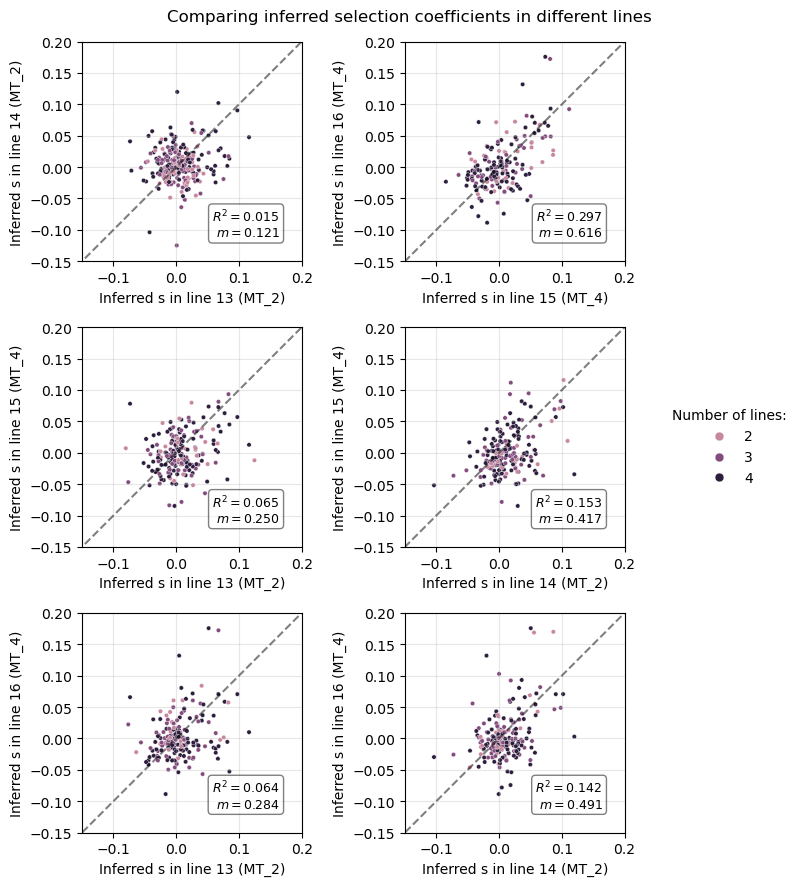

In [6]:
#Correlations of fitnesses of same mutations in different lines
fig, axes = plt.subplots(3,2,figsize=(8,9))
axes = axes.flatten()
colours = sns.color_palette("ch:", n_colors=4).as_hex()
custom_palette = {2: colours[1], 3: colours[2], 4: colours[3]}

line_1 = [13,15,13,14,13,14]
line_2 = [14,16,15,15,16,16]
MT_dict = {13:2,14:2,15:4,16:4}

for i,ax in enumerate(axes):
    #Plot scatters
    data = data_indexed[data_indexed['Max frequency']>0.1]
    overlapping_mutations = pd.merge(data[data['line']==line_1[i]][['s','Index','number_of_lines']],data[data['line']==line_2[i]][['s','Index']], on='Index', how='inner')
    sns.scatterplot(data=overlapping_mutations, x='s_x', y='s_y', ax=ax, hue='number_of_lines', palette=custom_palette, s=10) 
    
    #Linear regression
    m, c, r, p, std_err = stats.linregress(overlapping_mutations['s_x'],overlapping_mutations['s_y'])
    ax.text(0.9, 0.1, f'$R^2 = {r**2:.3f}$\n$m={m:.3f}$', transform=ax.transAxes, fontsize=9, verticalalignment='bottom',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    #Format
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
    ax.grid(alpha=0.3)
    ax.plot(np.linspace(-0.3,0.2,10),np.linspace(-0.3,0.2,10),'--',color='black',alpha=0.5)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(f'Inferred s in line {line_1[i]} (MT_{MT_dict[line_1[i]]})')
    ax.set_ylabel(f'Inferred s in line {line_2[i]} (MT_{MT_dict[line_2[i]]})')
    ax.set_xlim(-0.15,0.2)
    ax.set_ylim(-0.15,0.2)


fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.9, 0.55), ncol=1, title='Number of lines:', frameon=False, markerscale=2)
plt.suptitle('Comparing inferred selection coefficients in different lines')
plt.tight_layout()
plt.subplots_adjust(right=0.8, hspace=0.3, wspace=0.2)
plt.savefig(fig_path + f"/parallel_mutations_correlations.pdf")
plt.show()

Note here we are comparing only mutations that got to at least 0.1 in both lines. Changing sampling depth doesn't increase correlations sigificantly.

## $ds$ distributions

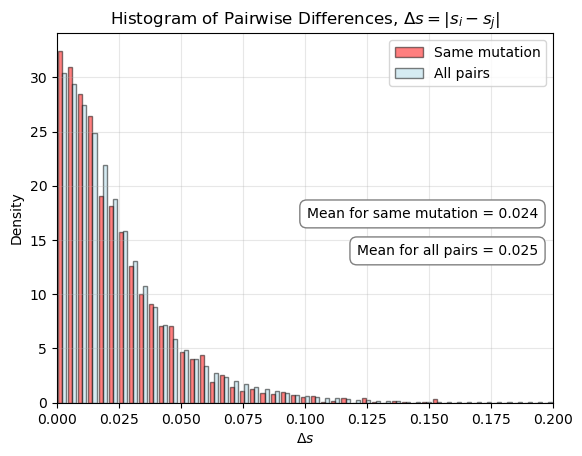

In [7]:
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")

#Get all ds values
s_values = data['s'].values
s_delta = np.abs(s_values[:, np.newaxis] - s_values)
s_delta = s_delta.flatten()

#Get ds values for same mutations
merged = data.merge(data, on=['pos', 'new'], suffixes=('_a', '_b'))
pairs = merged[merged.line_a != merged.line_b].copy()
pairs['delta_s'] = np.abs(pairs['s_a'] - pairs['s_b'])

#Plot
fig, ax = plt.subplots(1,1)
ax.hist([pairs['delta_s'],s_delta], bins=np.linspace(0,0.2,50), edgecolor='black',color=['red','lightblue'],density=True,alpha=0.5,label=['Same mutation','All pairs'])
pair_mean = pairs['delta_s'].mean()
ax.text(0.97,0.5,f'Mean for same mutation = {pair_mean:.3f}',fontsize=10,bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5'),transform=ax.transAxes, ha='right')
ax.text(0.97,0.4,f'Mean for all pairs = {s_delta.mean():.3f}',fontsize=10,bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5'),transform=ax.transAxes, ha='right')
ax.set_title('Histogram of Pairwise Differences, $\Delta s = |s_i - s_j|$')
ax.set_xlabel('$\Delta s$')
ax.grid(alpha=0.3)
ax.set_ylabel('Density')
ax.legend()
ax.set_xlim(0,0.2)
plt.savefig(fig_path + f"/ds distributions.pdf")
plt.show()

In [8]:
#Randomisation test
num_tests = 1000
means = []
for _ in range(num_tests):
    mutations_table_shuffled = data.copy()
    mutations_table_shuffled['s shuffled'] = np.random.permutation(data['s'].values)

    merged = mutations_table_shuffled.merge(mutations_table_shuffled, on=['pos', 'new'], suffixes=('_a', '_b'))
    pairs = merged[merged.line_a != merged.line_b].copy()
    means.append((np.abs(pairs['s shuffled_a'] - pairs['s shuffled_b'])).mean())

print(f'p-value = {((means<pair_mean).sum()/num_tests):.4f}')

p-value = 0.0060


Significantly lower mean distance between selection coefficients of the same mutation.

## Figure SI9

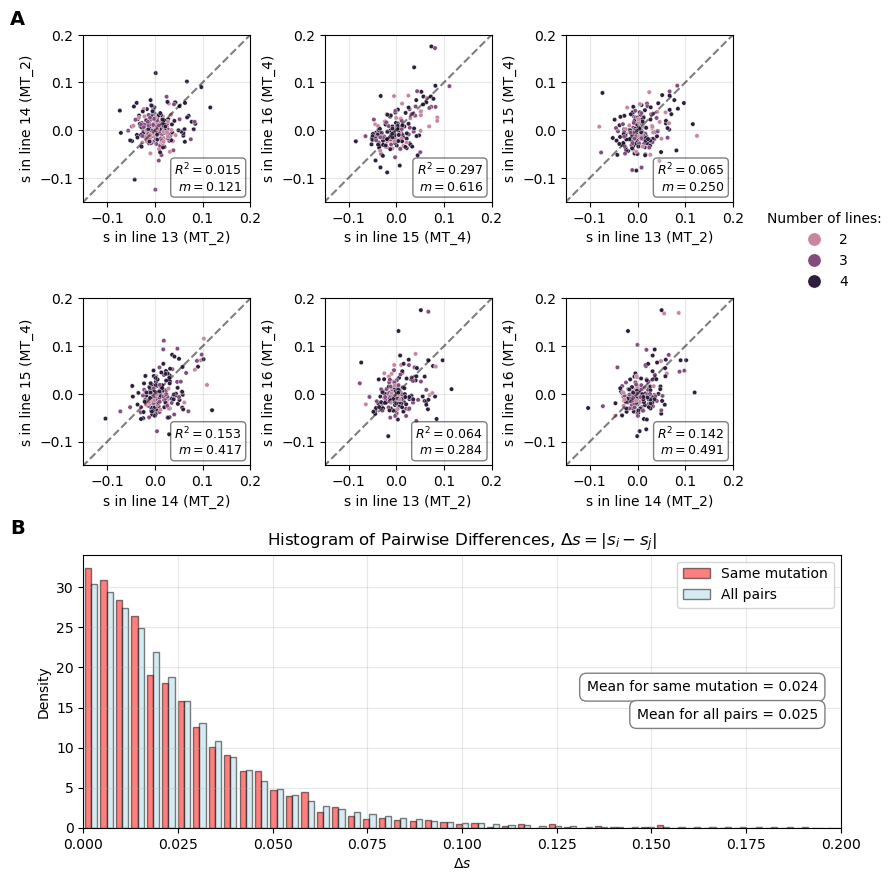

In [9]:
mosaic = [['A','B','C','L'],
          ['D','E','F','L'],
          ['G','G','G','G']]

fig, axes = plt.subplot_mosaic(mosaic,figsize=(9, 9),width_ratios=[1,1,1,0.2],height_ratios=[1,1,1.5])

#Mutation correlations
for i,ax in enumerate([axes['A'],axes['B'],axes['C'],axes['D'],axes['E'],axes['F']]):
    #Plot scatters
    data = data_indexed[data_indexed['Max frequency']>0.1]
    overlapping_mutations = pd.merge(data[data['line']==line_1[i]][['s','Index','number_of_lines']],data[data['line']==line_2[i]][['s','Index']], on='Index', how='inner')
    sns.scatterplot(data=overlapping_mutations, x='s_x', y='s_y', ax=ax, hue='number_of_lines', palette=custom_palette, s=10) 
    
    #Linear regression
    m, c, r, p, std_err = stats.linregress(overlapping_mutations['s_x'],overlapping_mutations['s_y'])
    ax.text(0.95, 0.05, f'$R^2 = {r**2:.3f}$\n$m={m:.3f}$', transform=ax.transAxes, fontsize=9, verticalalignment='bottom',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    #Format
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
    ax.grid(alpha=0.3)
    ax.plot(np.linspace(-0.3,0.2,10),np.linspace(-0.3,0.2,10),'--',color='black',alpha=0.5)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(f's in line {line_1[i]} (MT_{MT_dict[line_1[i]]})')
    ax.set_ylabel(f's in line {line_2[i]} (MT_{MT_dict[line_2[i]]})')
    ax.set_xlim(-0.15,0.2)
    ax.set_ylim(-0.15,0.2)

axes['A'].text(-0.35, 1.15, 'A', transform=axes['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')
handles, labels = axes['A'].get_legend_handles_labels()
axes['L'].axis('off')
axes['L'].legend(handles, labels, loc='center', title='Number of lines:', frameon=False, markerscale=3)


#ds distributions
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")

#Get all ds values
s_values = data['s'].values
s_delta = np.abs(s_values[:, np.newaxis] - s_values)
s_delta = s_delta.flatten()

#Get ds values for same mutations
merged = data.merge(data, on=['pos', 'new'], suffixes=('_a', '_b'))
pairs = merged[merged.line_a != merged.line_b].copy()
pairs['delta_s'] = np.abs(pairs['s_a'] - pairs['s_b'])

#Plot
axes['G'].hist([pairs['delta_s'],s_delta], bins=np.linspace(0,0.2,50), edgecolor='black',color=['red','lightblue'],density=True,alpha=0.5,label=['Same mutation','All pairs'])
pair_mean = pairs['delta_s'].mean()
axes['G'].text(0.97,0.5,f'Mean for same mutation = {pair_mean:.3f}',fontsize=10,bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5'),transform=axes['G'].transAxes, ha='right')
axes['G'].text(0.97,0.4,f'Mean for all pairs = {s_delta.mean():.3f}',fontsize=10,bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5'),transform=axes['G'].transAxes, ha='right')
axes['G'].set_title('Histogram of Pairwise Differences, $\Delta s = |s_i - s_j|$')
axes['G'].set_xlabel('$\Delta s$')
axes['G'].grid(alpha=0.3)
axes['G'].set_ylabel('Density')
axes['G'].legend()
axes['G'].set_xlim(0,0.2)
axes['G'].text(-0.35, -1.9, 'B', transform=axes['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(fig_path + f"/Figure_SI9.pdf")
plt.show()

## Beneficial tail

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_53407/3336653165.py:15: RuntimeWarning: invalid value encountered in power
  y = ((1 + k*x/t)**(-(k+1)/k))/t


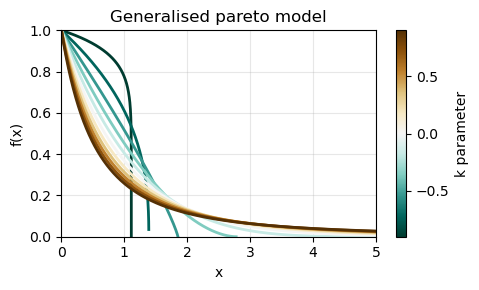

In [10]:
#Plot generalised pareto model distributions (GPM) for different k
x = np.linspace(0, 5, 10000)
t = 1
k_ = np.linspace(-0.9, 0.9, 11)

#Plot distributions
cmap = plt.get_cmap('BrBG_r') 
norm = mcolors.TwoSlopeNorm(vmin=-0.9, vcenter=0, vmax=0.9)
fig, ax = plt.subplots(1, 1, figsize=(5, 3))

for k in k_:
    if np.abs(k) < 0.001:
        y = np.exp(-x/t)/t
    else:
        y = ((1 + k*x/t)**(-(k+1)/k))/t
    
    ax.plot(x, y, color=cmap(norm(k)), lw=2)

#Format
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('k parameter')

ax.grid(alpha=0.3)
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.set_xlim(0,5)
ax.set_ylim(0,1)
plt.title("Generalised pareto model")
plt.tight_layout()
plt.savefig(fig_path + f"/generalised_pareto_distributions.pdf")
plt.show()

In [11]:
#Determine most likely distribution for data
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")

for j in range(4):

    #Get beneficial tail
    data_line = data[data['line']==j+13].copy()
    s_line = data_line['s']
    s_ben_line = s_line[s_line>0]

    #Fit exponential model, pdf = 1/l exp(-x/l)
    _, l_fit = expon.fit(s_ben_line, floc=0) 
    log_likelihood_expon = np.sum(expon.logpdf(s_ben_line, 0, l_fit))

    #Fit generalised pareto model, pdf = (1/t)((1+kx/t)**(-(k+1)/k))
    k_fit, _, t_fit = genpareto.fit(s_ben_line, floc=0) 
    log_likelihood_genpareto = np.sum(genpareto.logpdf(s_ben_line, k_fit, 0, t_fit))

    #Likelihood ratio test
    likelihood_ratio = -2*(log_likelihood_expon - log_likelihood_genpareto)
    p_value = chi2.sf(likelihood_ratio, 1) #degrees of freedom = 1

    #Display results
    print(f'  Line {j+13}:')
    if p_value > 0.05:
        print(f"p-value = {p_value:.3f}>0.05, so exponential is not rejected")
    else:
        print(f"p-value = {p_value:.7f}<0.05, so exponential is rejected in favour of GPM, parameter {k_fit:.3f}")

  Line 13:
p-value = 0.596>0.05, so exponential is not rejected
  Line 14:
p-value = 0.638>0.05, so exponential is not rejected
  Line 15:
p-value = 0.0001154<0.05, so exponential is rejected in favour of GPM, parameter 0.168
  Line 16:
p-value = 0.0000003<0.05, so exponential is rejected in favour of GPM, parameter 0.211


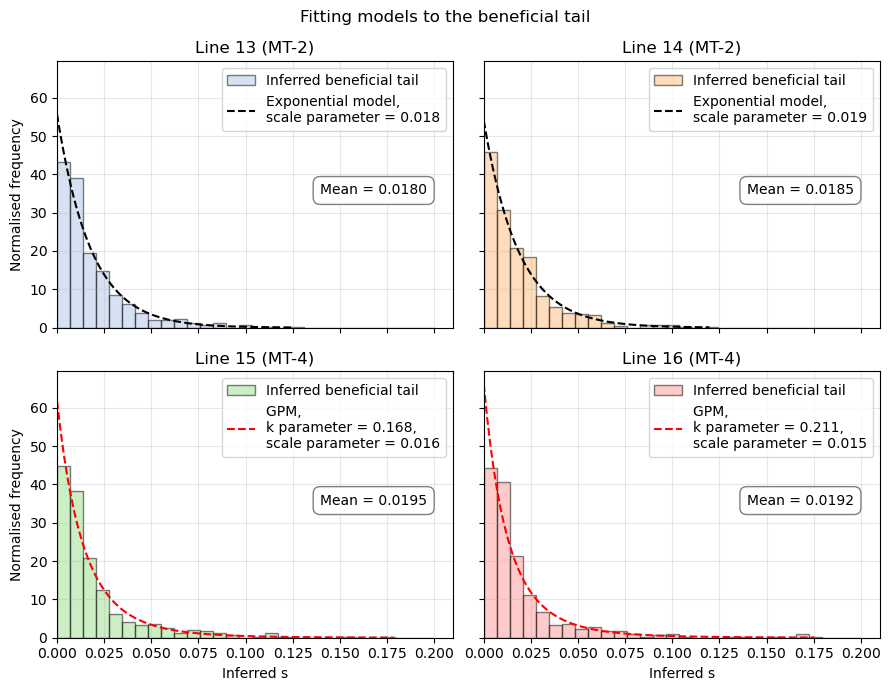

In [12]:
#Plot best fits
fig, axes = plt.subplots(2,2,figsize=(9,7),sharex=True,sharey=True)
axes = axes.flatten()
cmap = plt.get_cmap('tab20')
colours = [cmap(i)[:3] for i in range(20)]

for j,ax in enumerate(axes):
    #Get beneficial tail
    data_line = data[data['line']==j+13].copy()
    s_line = data_line['s']
    s_ben_line = s_line[s_line>0]
    ax.hist(s_ben_line, density=True, bins=np.linspace(0,0.2,30),alpha=0.5,edgecolor='black',facecolor=colours[1+2*j], label='Inferred beneficial tail')
    
    #Plot best fit line
    x = np.linspace(0, max(s_ben_line), 100)
    if j < 2:
        #Fit exponential model, pdf = 1/l exp(-x/l)
        _, l_fit = expon.fit(s_ben_line, floc=0) 
        ax.plot(x, expon.pdf(x, 0, l_fit), '--', color='black', label=f'Exponential model, \nscale parameter = {l_fit:.3f}')
    

    else:
        #Fit generalised pareto model, pdf = (1/t)((1+kx/t)**(-(k+1)/k))
        k_fit, _, t_fit = genpareto.fit(s_ben_line, floc=0) 
        ax.plot(x, genpareto.pdf(x, k_fit, 0, t_fit), '--', color='red', label=f'GPM, \nk parameter = {k_fit:.3f}, \nscale parameter = {t_fit:.3f}')

    #Plot mean
    ax.text(0.8,0.5,f'Mean = {s_ben_line.mean():.4f}',fontsize=10,bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5'),transform=ax.transAxes, ha='center')

    #Format
    ax.set_title(f'Line {j+13} (MT-{(np.floor(j/2)*2 +2).astype(int)})')
    ax.grid(alpha=0.3)
    ax.set_xlim(left=0)
    ax.legend()
    if j > 1:
        ax.set_xlabel('Inferred s')
    if j==0 or j==2:
        ax.set_ylabel('Normalised frequency')


plt.suptitle("Fitting models to the beneficial tail")
plt.tight_layout()
plt.savefig(fig_path + f"/beneficial_tails.pdf")
plt.show()

In [13]:
#Bootstrapping to test robustness of fit
number_bootstraps = 1000

#Determine most likely distribution
for j in range(4):

    #Get beneficial tail
    data_line = data[data['line']==j+13].copy()
    s_line = data_line['s']
    s_ben_line = s_line[s_line>0]

    p_values = []
    k_values = []
    for k in range(number_bootstraps):
        #Sample
        s_ben_sample = s_ben_line.sample(n=len(s_ben_line),replace=True)

        #Fit exponential model, pdf = 1/l exp(-x/l)
        _, l_fit = expon.fit(s_ben_sample, floc=0) 
        log_likelihood_expon = np.sum(expon.logpdf(s_ben_sample, 0, l_fit))

        #Fit generalised pareto model, pdf = (1/t)((1+kx/t)**(-(k+1)/k))
        k_fit, _, t_fit = genpareto.fit(s_ben_sample, floc=0) 
        log_likelihood_genpareto = np.sum(genpareto.logpdf(s_ben_sample, k_fit, 0, t_fit))

        #Likelihood ratio test
        likelihood_ratio = -2*(log_likelihood_expon - log_likelihood_genpareto)
        p_value = chi2.sf(likelihood_ratio, 1) #degrees of freedom = 1

        k_values.append(k_fit)
        p_values.append(p_value)

    #Display results
    print(f'  Line {j+13}:')
    perc_significant = (np.array(p_values) < 0.05).sum()/number_bootstraps * 100
    print(f'Percentage of significant p-values = {perc_significant:.1f}%')
    significant_k = np.where((np.array(p_values) < 0.05),np.array(k_values),0)
    print(f'Percentage with k<0: {(significant_k<0).sum()/number_bootstraps * 100:.1f}%\nPercentage with k>0: {(significant_k>0).sum()/number_bootstraps * 100:.1f}%')


  Line 13:
Percentage of significant p-values = 5.6%
Percentage with k<0: 0.4%
Percentage with k>0: 5.2%
  Line 14:
Percentage of significant p-values = 4.9%
Percentage with k<0: 0.7%
Percentage with k>0: 4.2%
  Line 15:
Percentage of significant p-values = 96.2%
Percentage with k<0: 0.0%
Percentage with k>0: 96.2%
  Line 16:
Percentage of significant p-values = 99.6%
Percentage with k<0: 0.0%
Percentage with k>0: 99.6%


Also actually a slightly higher number of mutations (and mutations that fix) in MT2, despite (perhaps because of) it having a lower effective population size, and so there is a higher statistical power in MT2 with which to accept/reject the exponential.

## Diminishing returns

Here, just looking at those mutations that fix in each line (achieve >99%)

Number of fixed mutations in line 13 = 130
Number of fixed mutations in line 14 = 145
Number of fixed mutations in line 15 = 73
Number of fixed mutations in line 16 = 62


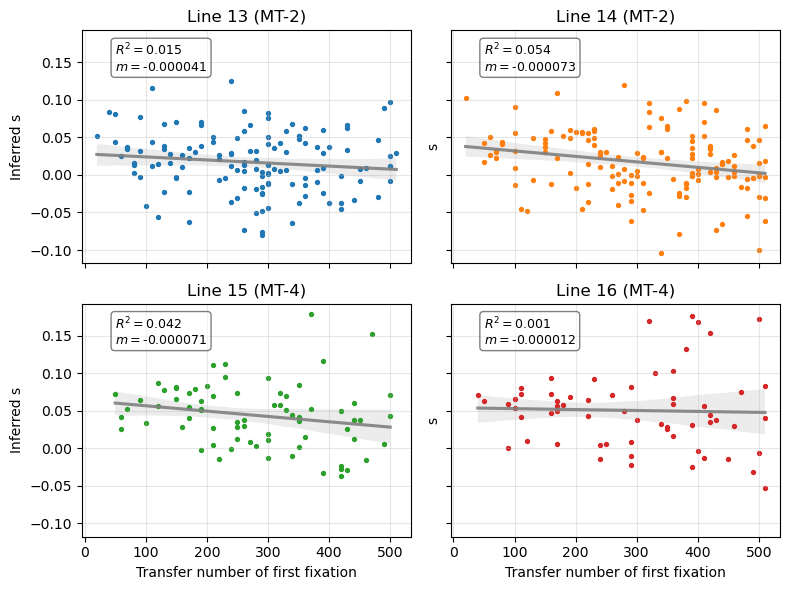

In [14]:
fig, axes = plt.subplots(2,2,figsize=(8,6),sharex=True,sharey=True)
axes = axes.flatten()
colours = ['tab:blue','tab:orange','tab:green','tab:red']

#Get fixation time
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")
data['Fix time'] = (data[np.arange(0,511,10)] > 0.99).idxmax(axis=1).astype(int)

for i,ax in enumerate(axes):

    #Get selection coefficients
    data_line = data[data['line']==i+13]
    fixed_mutations = data_line[data_line['Fix time']>0]
    print(f'Number of fixed mutations in line {i+13} = {len(fixed_mutations)}')

    #Plot
    sns.regplot(data=fixed_mutations, ax=ax, x='Fix time', y='s', scatter=False, line_kws={'alpha':0.9,'color':'grey'})
    ax.scatter(fixed_mutations['Fix time'],fixed_mutations['s'],color=colours[i],s=8)
    
    #Linear regression
    m, c, r, p, std_err = stats.linregress(fixed_mutations['Fix time'].astype(int),fixed_mutations['s'])
    ax.text(0.1, 0.95, f'$R^2 = ${r**2:.3f}\n$m = ${m:.6f}', transform=ax.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    #Format
    if  i>1:
        ax.set_xlabel('Transfer number of first fixation')
    else:
        ax.set_xlabel('')
    if i==0 or i==2:
        ax.set_ylabel('Inferred s')
    ax.grid(alpha=0.3)
    ax.set_title(f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})')

plt.tight_layout()
plt.savefig(fig_path + f"/diminishing_returns.pdf")
plt.show()

## Figure SI10

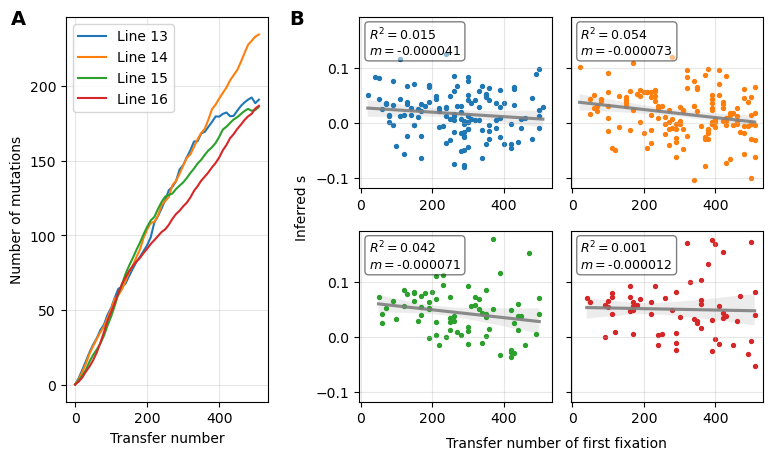

In [15]:
fig = plt.figure(figsize=(9, 5))

outer = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1, 2], wspace=0.3)
ax1 = fig.add_subplot(outer[0, 0])

inner = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=outer[0, 1], wspace=0.1, hspace=0.25)
ax2 = fig.add_subplot(inner[0, 0])
ax3 = fig.add_subplot(inner[0, 1])
ax4 = fig.add_subplot(inner[1, 0])
ax5 = fig.add_subplot(inner[1, 1])

ax3.sharey(ax2)
ax4.sharey(ax2)
ax5.sharey(ax2)
ax3.sharex(ax2)
ax4.sharex(ax2)
ax5.sharex(ax2)

colours = ['tab:blue','tab:orange','tab:green','tab:red']
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")

#Mutations over time
mean_no_muts = np.zeros((4,52))
for i in range(4):
    data_line = data.loc[data['line'] == i+13]
    mean_no_muts[i,:] = data_line[np.arange(0,511,10)].sum(axis=0)

for i in range(4):
    ax1.plot(np.arange(0,511,10),mean_no_muts[i,:],label=f'Line {i+13}',color=colours[i])
ax1.set_xlabel('Transfer number')
ax1.set_ylabel("Number of mutations")
ax1.grid(alpha=0.3)
ax1.legend()
ax1.text(-0.2, 1.02, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Diminishing returns
data['Fix time'] = (data[np.arange(0,511,10)] > 0.99).idxmax(axis=1).astype(int)
for i,ax in enumerate([ax2,ax3,ax4,ax5]):

    #Get selection coefficients
    data_line = data[data['line']==i+13]
    fixed_mutations = data_line[data_line['Fix time']>0]

    #Plot
    sns.regplot(data=fixed_mutations, ax=ax, x='Fix time', y='s', scatter=False, line_kws={'alpha':0.9,'color':'grey'})
    ax.scatter(fixed_mutations['Fix time'],fixed_mutations['s'],color=colours[i],s=8)
    
    #Linear regression
    m, c, r, p, std_err = stats.linregress(fixed_mutations['Fix time'].astype(int),fixed_mutations['s'])
    ax.text(0.05, 0.95, f'$R^2 = ${r**2:.3f}\n$m = ${m:.6f}', transform=ax.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    ax.grid(alpha=0.3)


#Format
for ax in ([ax2,ax4]):
  ax.tick_params(axis="y", which="both", left=True, labelleft=True)
  ax.set_xlabel('')
  ax.set_ylabel('')

for ax in ([ax3,ax5]):
  ax.tick_params(axis="y", which="both", left=True, labelleft=False)
  ax.set_ylabel('')
  ax.set_xlabel('')

ax2.text(1.18, 1.02, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

fig.text(0.67,0.02,'Transfer number of first fixation',ha='center',fontsize=10)
fig.text(0.38,0.5,'Inferred s',va='center',fontsize=10,rotation=90)

plt.savefig(fig_path + f"/Figure_SI10.pdf")
plt.show()

## True vs. estimated covariance

In this section, we only look at substitution mutations, not indels

In [16]:
@njit
def update_matrix(matrix, seq_ints, qual_scores, start_pos, q_cutoff):
    #Fast numba function for counting pairs of amino acids
    n = len(seq_ints)
    for i in range(n):
        if qual_scores[i] < q_cutoff: continue
        
        row_idx = (start_pos + i) * 4 + seq_ints[i]
        for j in range(i, n):
            if qual_scores[j] < q_cutoff: continue

            col_idx = (start_pos + j) * 4 + seq_ints[j]
            matrix[row_idx, col_idx] += 1


#For converting sequences to integers
map_arr = np.zeros(256, dtype=np.int8)
map_arr[ord('A')] = 0
map_arr[ord('C')] = 1
map_arr[ord('G')] = 2
map_arr[ord('T')] = 3

#### One sample

In [17]:
#True covariance from one sample
file_path = os.path.join(data_path + '/13', os.listdir(data_path + '/13')[0])
Nij = np.zeros((10000*4,10000*4))

with pysam.AlignmentFile(file_path, "rb") as bam:

    #Read each sequence in the BAM file
    for read in bam:
        if read.is_unmapped:
            continue

        #Transform sequence and quality scores into arrays of integers
        seq_ints = map_arr[np.frombuffer(read.query_sequence.encode(), dtype=np.int8)]
        qual_scores = np.array(read.query_qualities)

        # Call the Numba function
        update_matrix(Nij, seq_ints, qual_scores, read.reference_start, 36)

Nij_nan = np.where(Nij==0,np.nan,Nij)

Nij_nan = Nij_nan.astype(np.float32, copy=False)
xij = Nij_nan.reshape(10000, 4, 10000, 4)

pairwise_total = np.nansum(xij,axis=(1, 3), dtype=np.float32) #sum number of pairwise measurements
pairwise_total = np.where(pairwise_total == 0,np.nan,pairwise_total)

valid_blocks = pairwise_total >= 1000 #mask for counts threshold
pairwise_total = np.where(valid_blocks, pairwise_total, np.nan)

xij /= pairwise_total[:, np.newaxis, :, np.newaxis] #find frequencies
xij = xij.reshape(40000, 40000) #reshape back to 2D

xij[xij < 0.001] = np.nan #Apply frequency threshold

x = np.diag(xij).astype(np.float32, copy=True) #Calculate individual frequencies

cov = xij - np.outer(x, x) #calculate covariance

#Get full covariance matrix
cov = np.where(np.isnan(cov),0,cov)
cov += cov.T
np.fill_diagonal(cov,x*(1-x))
cov = np.where(cov==0,np.nan,cov)

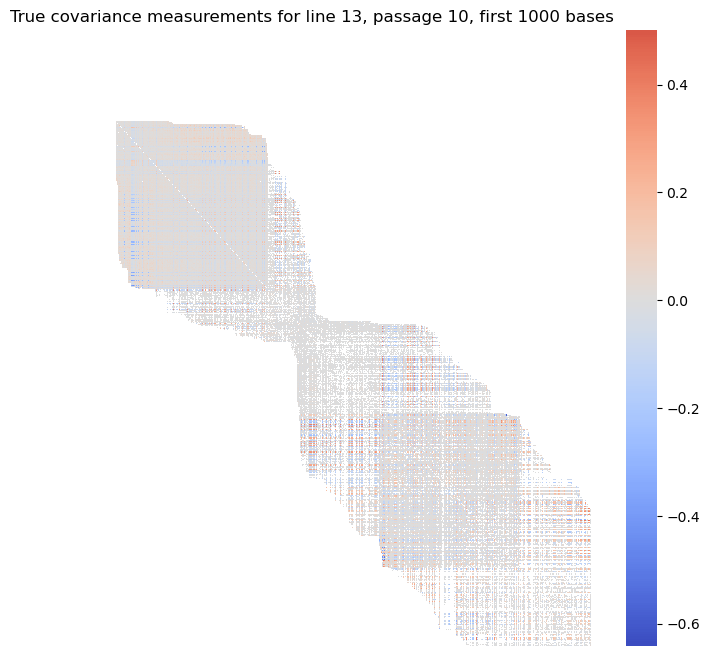

In [18]:
#Plot true covariance matrix
fig, ax = plt.subplots(1,1,figsize=(9,8))
sns.heatmap(cov[:4000,:4000],cmap='coolwarm',center=0,xticklabels=False, yticklabels=False)
ax.tick_params(left=False, bottom=False)
plt.title('True covariance measurements for line 13, passage 10, first 1000 bases',fontsize=12)
plt.savefig(fig_path + f"/true_covariance_one_sample.pdf")
plt.show()

white = no data

The width of the band is around 250 base pairs, the maximum length of the individual reads.    

There are gaps at the start and end of around 150 base pairs - these are the primer binding sites for the first and last amplicons so cannot be sequenced.  

There are then 'bulbs' of around 500 base pairs on each end, where none of these pairs link with the main body - these could be due to a primer failure during amplification or a cutting hotspot during fragmentation. This often can happen in the LTR regions as they are structurally complex, and the 'bulbs' seem to cover exactly the LTR regions.  It could also be due to these reads being mapped onto the opposite end as the LTR regions are identical.

The sequencing ends around 9750bp.  

#### All samples

In [ ]:
#Get true covariances from all sequence data for positions with recorded mutations (~4.5 hours)

#Initiate true covariance matrices 
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")
data = data[data['type']=='substitution']

sampled_covariances = [] 
for line in [13,14,15,16]:
    mutations_table_line = data[data['line'] == line]
    sampled_covariance = np.zeros((len(mutations_table_line), len(mutations_table_line), 51))
    sampled_covariances.append(sampled_covariance)

#Get sequencing data from each line in turn
for line in [13,14,15,16]:
    folder_path = data_path + f"/{line}"

    #Open each sequence file in turn
    for filename in os.listdir(folder_path):
        
        if filename.endswith(".bam"):
            file_path = os.path.join(folder_path, filename)

            #Get passage number
            passage_num = file_path.split('P')[-1].split('seq')[0]
            if 'FullRep' in passage_num:
                passage_num = passage_num.split('FullRep')[0]
            if 'combined' in passage_num:
                passage_num = passage_num.split('combined')[0]
            passage_num = int(passage_num)

            if passage_num < 511:
                Nij = np.zeros((10000*4,10000*4))

                with pysam.AlignmentFile(file_path, "rb") as bam:

                    #Read each sequence in the BAM file
                    for read in bam:
                        if read.is_unmapped:
                            continue

                        #Transform sequence and quality scores into arrays of integers
                        seq_ints = map_arr[np.frombuffer(read.query_sequence.encode(), dtype=np.int8)]
                        qual_scores = np.array(read.query_qualities)

                        # Call the Numba function
                        update_matrix(Nij, seq_ints, qual_scores, read.reference_start, 36)



                #Calculate frequencies 
                Nij_nan = np.where(Nij==0,np.nan,Nij)
                Nij_nan = Nij_nan.astype(np.float32, copy=False)
                xij = Nij_nan.reshape(10000, 4, 10000, 4)

                pairwise_total = np.nansum(xij,axis=(1, 3), dtype=np.float32) #sum number of pairwise measurements
                pairwise_total = np.where(pairwise_total == 0,np.nan,pairwise_total)

                valid_blocks = pairwise_total >= 1000 #mask for counts threshold
                pairwise_total = np.where(valid_blocks, pairwise_total, np.nan)

                xij /= pairwise_total[:, np.newaxis, :, np.newaxis] #find frequencies
                xij = xij.reshape(40000, 40000) #reshape back to 2D

                xij[xij < 0.001] = np.nan #Apply frequency threshold

                x = np.diag(xij).astype(np.float32, copy=True) #Calculate individual frequencies

                #Get full covariance matrix
                cov = xij - np.outer(x, x) #calculate covariance
                cov = np.where(np.isnan(cov),0,cov)
                cov += cov.T
                np.fill_diagonal(cov,x*(1-x))
                cov = np.where(cov==0,np.nan,cov)


                #Sample covariance (swap lines 15 and 16 after passage 360)
                if line == 15 and passage_num > 360:
                    data_line = data[data['line'] == 16]
                elif line == 16 and passage_num > 360:
                    data_line = data[data['line'] == 15]
                else:
                    data_line = data[data['line'] == line]

                idxs = []
                for p,a in zip(data_line['pos'], data_line['new']):
                    idxs.append(p*4 + 'ACGT'.index(a))
                idxs = np.array(idxs, dtype=int)

                if line == 15 and passage_num > 360:
                    sampled_covariances[3][:,:,int(passage_num/10 -1)] = cov[np.ix_(idxs, idxs)]
                elif line == 16 and passage_num > 360:
                    sampled_covariances[2][:,:,int(passage_num/10 -1)] = cov[np.ix_(idxs, idxs)]
                else:
                    sampled_covariances[line-13][:,:,int(passage_num/10 -1)] = cov[np.ix_(idxs, idxs)]


#Save covariances
np.savez_compressed(out_path + '/true_covariances.npz', line13=sampled_covariances[0], line14=sampled_covariances[1], line15=sampled_covariances[2], line16=sampled_covariances[3])

#### Compare true vs. estimated

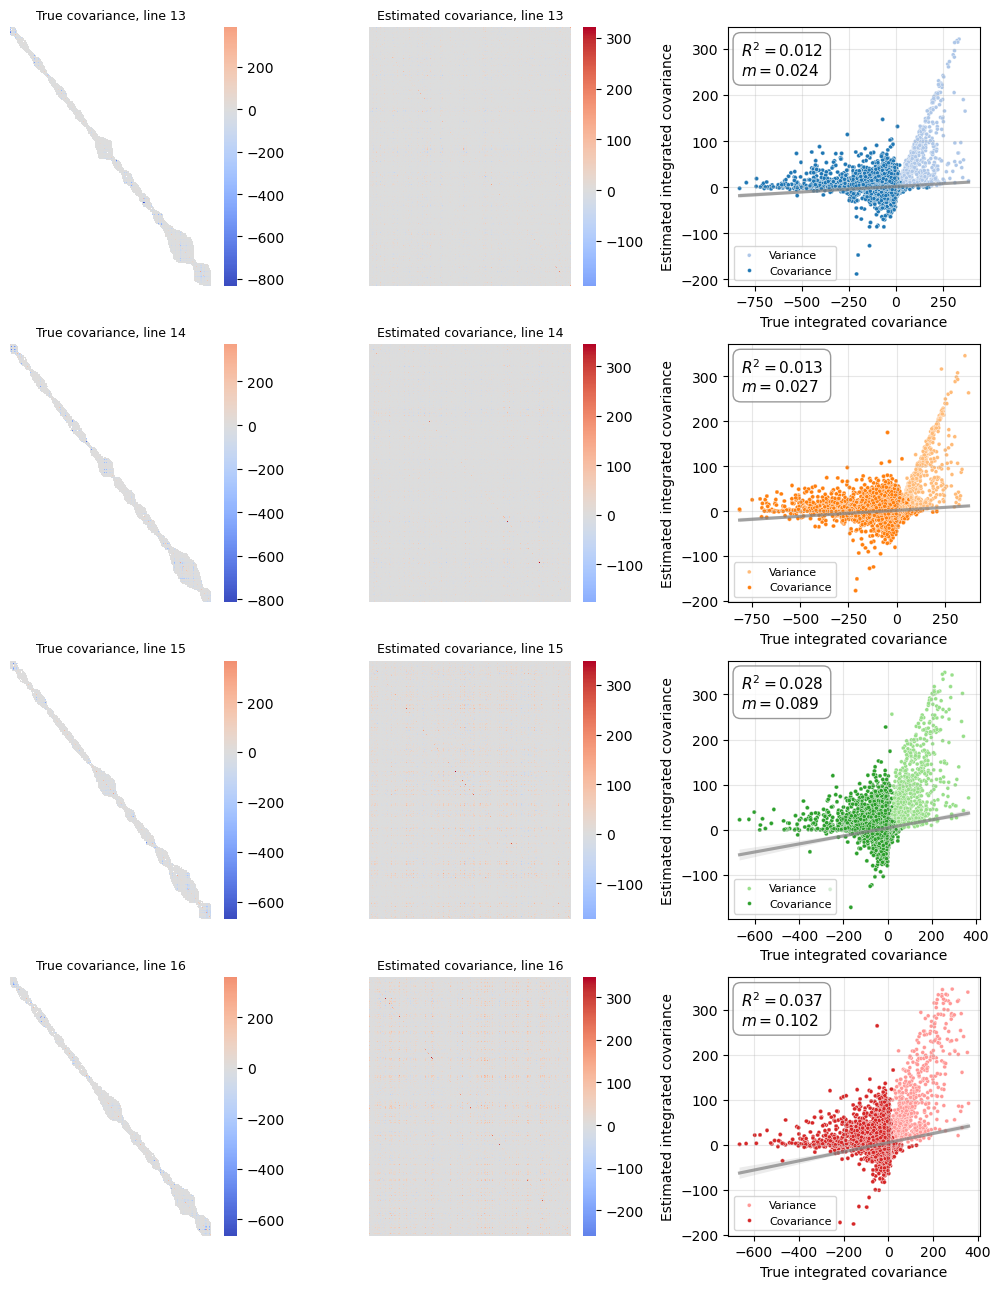

In [20]:
#Compare true and estimated covariances
data = pd.read_pickle(out_path + "/mutation_time_series.pkl")
true_covariances = np.load(out_path + "/true_covariances.npz")
estimated_covariances = np.load(out_path + "/estimated_covariances.npz")

fig, axes = plt.subplots(4,3,figsize=(10,13))
cmap = plt.get_cmap('tab20')
colours = [cmap(i)[:3] for i in range(20)]

for i,line in enumerate([13,14,15,16]):

    #Get true covariances: remove consensus rows and integrate over time
    data_line = data[(data['line']==line) & (data['type']=='substitution')].reset_index(drop=True)
    idxs = data_line[data_line['details']!='consensus'].index
    true_covariance_int = true_covariances[f'line{line}'][np.ix_(idxs,idxs)].sum(axis=2)*35
    true_covariance_int = np.where(true_covariance_int==0,np.nan,true_covariance_int)
    sns.heatmap(true_covariance_int,ax=axes[i,0],cmap='coolwarm',center=0,xticklabels=False, yticklabels=False)
    axes[i,0].tick_params(left=False, bottom=False)
    axes[i,0].set_title(f'True covariance, line {line}',fontsize=9)

    #Get estimated covariances: remove indels
    data_line = data[(data['line']==line) & (data['details']!='consensus')].reset_index(drop=True)
    idxs = data_line[data_line['type']=='substitution'].index
    estimated_covariances_subs = estimated_covariances[f'line{line}'][np.ix_(idxs,idxs)]
    sns.heatmap(estimated_covariances_subs,ax=axes[i,1],cmap='coolwarm',center=0,xticklabels=False, yticklabels=False)
    axes[i,1].tick_params(left=False, bottom=False)
    axes[i,1].set_title(f'Estimated covariance, line {line}',fontsize=9)

    #Compare true and estimated covariance
    mask = ~np.isnan(true_covariance_int.flatten())

    palette = {0: colours[2*i], 1: colours[2*i+1]}
    scatter_data = pd.DataFrame(data={'true':true_covariance_int.flatten()[mask],'estimated':estimated_covariances_subs.flatten()[mask],'variance':np.identity(true_covariance_int.shape[0]).flatten()[mask]})
    
    sns.scatterplot(data=scatter_data, x='true', y='estimated', ax=axes[i,2], hue='variance', palette=palette, edgecolor="white",s=8,legend=True)
    sns.regplot(data=scatter_data, x='true', y='estimated', ax=axes[i,2], scatter=False, line_kws={'alpha':0.7,'color':'grey'})

    m,_,r,_,_ = stats.linregress(scatter_data["true"], scatter_data["estimated"])
    axes[i,2].text(0.05,0.95,f"$R^2 = {r**2:.3f}$\n$m={m:.3f}$",transform=axes[i,2].transAxes,fontsize=11,verticalalignment="top",bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"))

    axes[i,2].legend(title='',labels=['Variance','Covariance'],loc='lower left',fontsize=8)
    axes[i,2].set_xlabel('True integrated covariance')
    axes[i,2].set_ylabel('Estimated integrated covariance')
    axes[i,2].grid(alpha=0.3)
    
plt.tight_layout()
plt.savefig(fig_path + f"/true_vs_estimated_covariance.pdf")
plt.show()

In [21]:
def plot_box_plot(ax, data, x):
    ax.plot(x+np.linspace(-0.3,0.3,5),np.median(data)+np.zeros(5),'--',color='black',linewidth=1)
    q1 = np.percentile(data,25)
    q2 = np.percentile(data,75)
    ax.plot(x+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=1)
    ax.plot(x+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5),np.linspace(q2,data.max(),5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5),np.linspace(data.min(),q1,5),'--',color='black',linewidth=1)
    ax.plot(x+np.linspace(-0.1,0.1,5),data.max()+np.zeros(5),'--',color='black',linewidth=1)
    ax.plot(x+np.linspace(-0.1,0.1,5),data.min()+np.zeros(5),'--',color='black',linewidth=1)

For line 13; covariance has a magnitude 0.0058 +/-0.0008 (mean +/-std)
For line 14; covariance has a magnitude 0.0057 +/-0.0008 (mean +/-std)
For line 15; covariance has a magnitude 0.0054 +/-0.0007 (mean +/-std)
For line 16; covariance has a magnitude 0.0055 +/-0.0008 (mean +/-std)


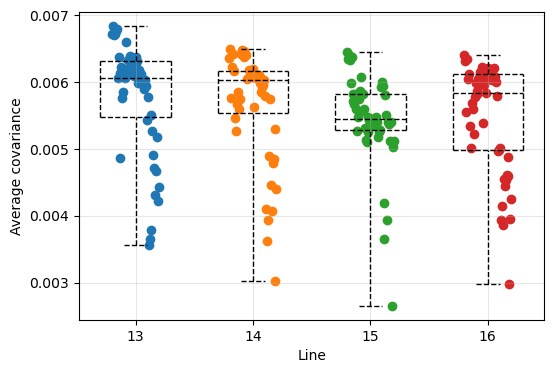

In [22]:
#Calculate magnitudes of true covariance data
fig, ax = plt.subplots(1,1,figsize=(6,4))
colours = ['tab:blue','tab:orange','tab:green','tab:red']
all_means = np.zeros((4,51))
for i,line in enumerate([13, 14, 15, 16]):
    cov_true = true_covariances[f'line{line}']
    mask = ~np.eye(cov_true.shape[0], dtype=bool)[:, :, None]
    means = np.abs(cov_true*mask).sum(axis=(0, 1)) / mask.sum(axis=(0, 1))
    all_means[i,:] = means

    print(f'For line {line}; covariance has a magnitude {np.mean(means):.4f} +/-{np.std(means):.4f} (mean +/-std)')
    ax.scatter(i+np.linspace(-0.2,0.2,len(means)),means,color=colours[i])
    plot_box_plot(ax, means, i)

plt.xticks(ticks=np.arange(4),labels=['13','14','15','16'])
plt.ylabel('Average covariance')
plt.xlabel('Line')
plt.grid(alpha=0.3)
plt.savefig(fig_path + f"/true_covariance_each_line.pdf")
plt.show()

Paired t-test p-value: 0.000008


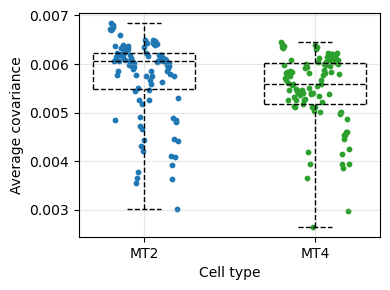

In [23]:
#Paired t-test for cell type
t_statistic, p_value = stats.ttest_rel(all_means[:2,:].flatten(), all_means[2:,:].flatten())
print(f"Paired t-test p-value: {p_value:.6f}")

#Plot box plots of covariance for each cell type
fig, ax = plt.subplots(1,1,figsize=(4,3))

ax.scatter(np.linspace(-0.2,0.2,102),all_means[:2,:].flatten(),s=10,color=colours[0])
plot_box_plot(ax, all_means[:2,:].flatten(), 0)

ax.scatter(np.linspace(0.8,1.2,102),all_means[2:,:].flatten(),s=10,color=colours[2])
plot_box_plot(ax, all_means[2:,:].flatten(), 1)

plt.xticks(ticks=np.arange(2),labels=['MT2','MT4'])
plt.ylabel('Average covariance')
plt.xlabel('Cell type')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(fig_path + f"/true_covariance_each_cell_type.pdf")
plt.show()

## Figure SI14

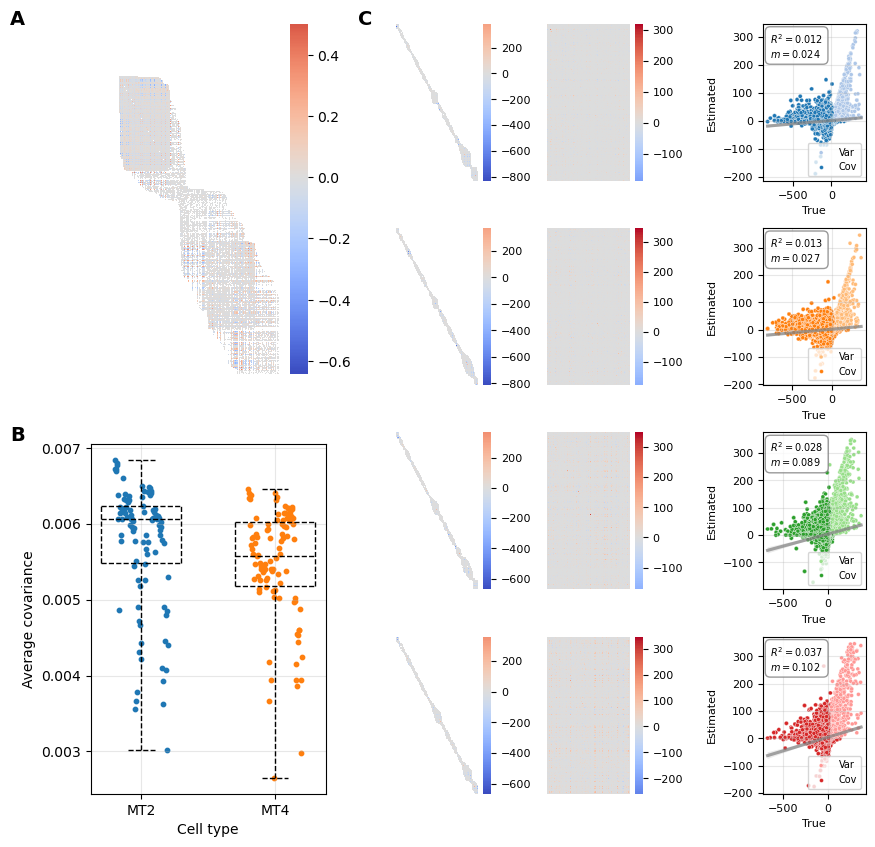

In [28]:
fig = plt.figure(figsize=(10, 10))

outer = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1, 2], wspace=0.2, hspace=0.2)
ax1 = fig.add_subplot(outer[0,0])
ax2 = fig.add_subplot(outer[1,0])
ax3 = fig.add_subplot(outer[0:2,1])
ax3.axis('off')

inner = gridspec.GridSpecFromSubplotSpec(4, 4, subplot_spec=outer[0:2,1], width_ratios=[1,1,0.15,1], wspace=0.6, hspace=0.3)
axes = []
for i in range(4):
    axes_row = []
    axes_row.append(fig.add_subplot(inner[i,0]))
    axes_row.append(fig.add_subplot(inner[i,1]))
    axes_row.append(fig.add_subplot(inner[i,3]))
    axes.append(axes_row)

#One true covariance sample
sns.heatmap(cov[:4000,:4000],ax=ax1,cmap='coolwarm',center=0,xticklabels=False, yticklabels=False)
ax1.tick_params(left=False, bottom=False)
ax1.text(-0.35, 1.04, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Magnitude of covariance between cell types
ax2.scatter(np.linspace(-0.2,0.2,102),all_means[:2,:].flatten(),s=10,color=colours[0])
plot_box_plot(ax2, all_means[:2,:].flatten(), 0)

ax2.scatter(np.linspace(0.8,1.2,102),all_means[2:,:].flatten(),s=10,color=colours[2])
plot_box_plot(ax2, all_means[2:,:].flatten(), 1)

ax2.set_xticks(ticks=np.arange(2),labels=['MT2','MT4'])
ax2.set_ylabel('Average covariance')
ax2.set_xlabel('Cell type')
ax2.grid(alpha=0.3)
ax2.text(-0.35, -0.15, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#True vs estimated
cmap = plt.get_cmap('tab20')
colours = [cmap(i)[:3] for i in range(20)]

for i,line in enumerate([13,14,15,16]):

    #Get true covariances: remove consensus rows and integrate over time
    data_line = data[(data['line']==line) & (data['type']=='substitution')].reset_index(drop=True)
    idxs = data_line[data_line['details']!='consensus'].index
    true_covariance_int = true_covariances[f'line{line}'][np.ix_(idxs,idxs)].sum(axis=2)*35
    true_covariance_int = np.where(true_covariance_int==0,np.nan,true_covariance_int)
    ax = sns.heatmap(true_covariance_int,ax=axes[i][0],cmap='coolwarm',center=0,xticklabels=False, yticklabels=False)
    axes[i][0].tick_params(left=False, bottom=False, labelbottom=False, labelleft=False)
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=8)

    #Get estimated covariances: remove indels
    data_line = data[(data['line']==line) & (data['details']!='consensus')].reset_index(drop=True)
    idxs = data_line[data_line['type']=='substitution'].index
    estimated_covariances_subs = estimated_covariances[f'line{line}'][np.ix_(idxs,idxs)]
    ax = sns.heatmap(estimated_covariances_subs,ax=axes[i][1],cmap='coolwarm',center=0,xticklabels=False, yticklabels=False)
    axes[i][1].tick_params(left=False, bottom=False, labelbottom=False, labelleft=False)
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=8)

    #Compare true and estimated covariance
    mask = ~np.isnan(true_covariance_int.flatten())

    palette = {0: colours[2*i], 1: colours[2*i+1]}
    scatter_data = pd.DataFrame(data={'true':true_covariance_int.flatten()[mask],'estimated':estimated_covariances_subs.flatten()[mask],'variance':np.identity(true_covariance_int.shape[0]).flatten()[mask]})
    
    sns.scatterplot(data=scatter_data, x='true', y='estimated', ax=axes[i][2], hue='variance', palette=palette, edgecolor="white",s=8,legend=True)
    sns.regplot(data=scatter_data, x='true', y='estimated', ax=axes[i][2], scatter=False, line_kws={'alpha':0.7,'color':'grey'})

    m,_,r,_,_ = stats.linregress(scatter_data["true"], scatter_data["estimated"])
    axes[i][2].text(0.07,0.95,f"$R^2 = {r**2:.3f}$\n$m={m:.3f}$",transform=axes[i][2].transAxes,fontsize=7,horizontalalignment="left",verticalalignment="top",bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"))

    axes[i][2].legend(title='',labels=['Var','Cov'],loc='lower right',fontsize=7)
    axes[i][2].set_xlabel('True',fontsize=8)
    axes[i][2].set_ylabel('Estimated',fontsize=8)
    axes[i][2].tick_params(labelsize=8)
    axes[i][2].grid(alpha=0.3)

ax3.text(1.5, 1.04, 'C', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.savefig(fig_path + f"/Figure_SI14.png")
plt.savefig(fig_path + f"/Figure_SI14.pdf")
plt.show()
